# B1 - Artificial Neural Network (tabular classification)

**Dataset:** Pima Indians Diabetes (OpenML, 768 rows, 8 numeric features, binary target).

**Plan:** preprocess (impute impossible zeros, scale) -> baseline ANN -> small tuning grid over hidden layers / activation / dropout -> final evaluation on a held-out test set.

In [1]:
import json, time, random
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

def save_result(name, d):
    """Persist metrics so the final comparison report can read them."""
    p = OUT / "results.json"
    r = json.loads(p.read_text()) if p.exists() else {}
    r[name] = d
    p.write_text(json.dumps(r, indent=2))

def plot_curves(h, title, fname):
    """Training-vs-validation loss and accuracy/metric curves."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(title + " - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["val_acc"], label="val")
    ax[1].set_title(title + " - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(OUT / fname, dpi=130); plt.show()


Device: cuda


In [2]:
def run_epoch(model, loader, loss_fn, opt=None):
    """One pass over loader. Trains if opt is given, else evaluates."""
    train = opt is not None
    model.train(train)
    tot_loss, preds, ys = 0.0, [], []
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(yb)
            preds.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return tot_loss / len(ys), accuracy_score(ys, preds), preds, ys

def fit(model, train_dl, val_dl, epochs, lr=1e-3, weight_decay=0.0, patience=None, verbose=True):
    """Adam + cross-entropy; keeps the best-val-loss weights. Returns history and train time."""
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, best_state, bad = 1e9, None, 0
    t0 = time.time()
    for ep in range(epochs):
        tl, ta, _, _ = run_epoch(model, train_dl, loss_fn, opt)
        vl, va, _, _ = run_epoch(model, val_dl, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        if vl < best:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose: print(f"ep {ep+1:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if patience and bad >= patience:
            print("early stop"); break
    model.load_state_dict(best_state)
    return h, time.time() - t0

def report(model, loader, names=None, average="binary"):
    _, _, p, y = run_epoch(model, loader, nn.CrossEntropyLoss())
    r = dict(accuracy=accuracy_score(y, p),
             precision=precision_score(y, p, average=average, zero_division=0),
             recall=recall_score(y, p, average=average, zero_division=0),
             f1=f1_score(y, p, average=average, zero_division=0))
    return r, p, y

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)


## 1. Load and inspect data

In [3]:
import pandas as pd
from sklearn.datasets import fetch_openml
df = fetch_openml(name="diabetes", version=1, as_frame=True).frame
df["class"] = (df["class"] == "tested_positive").astype(int)
print(df.shape); display(df.head()); print(df["class"].value_counts(normalize=True))
df.describe().T

(768, 9)


,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


class
0    0.651042
1    0.348958
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
preg,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
plas,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
pres,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
skin,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
insu,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
mass,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
pedi,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
class,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 2. Preprocessing
Columns such as glucose, blood pressure, skin thickness, insulin and BMI cannot physically be 0 - these zeros are missing values. We replace them with the **train-set median** (fit on train only to avoid leakage), then standardise. Split is 70/15/15 stratified.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

X = df.drop(columns="class"); y = df["class"].values
zero_cols = ["plas", "pres", "skin", "insu", "mass"]
X[zero_cols] = X[zero_cols].replace(0, np.nan)

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

med = X_tr.median()                       # medians from TRAIN only
X_tr, X_va, X_te = [d.fillna(med) for d in (X_tr, X_va, X_te)]
sc = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = [sc.transform(d).astype("float32") for d in (X_tr, X_va, X_te)]

def dl(X, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.long)), batch_size=32, shuffle=shuffle)
train_dl, val_dl, test_dl = dl(X_tr, y_tr, True), dl(X_va, y_va), dl(X_te, y_te)
print(X_tr.shape, X_va.shape, X_te.shape)

(537, 8) (115, 8) (116, 8)


## 3. Model definition
Configurable MLP: `hidden` = list of layer widths, `act` = activation, `p` = dropout.

In [5]:
ACTS = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}

class ANN(nn.Module):
    def __init__(self, in_dim, hidden=(32, 16), act="relu", p=0.2):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), ACTS[act](), nn.Dropout(p)]
            d = h
        layers.append(nn.Linear(d, 2))           # 2 logits (no-diabetes / diabetes)
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

print(ANN(8))

ANN(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=16, out_features=2, bias=True)
  )
)


## 4. Hyper-parameter tuning
Grid over hidden layers x activation x dropout (3x3x3 = 27 configs); each is trained with early stopping and ranked by **validation** loss/accuracy. The test set is untouched until the end.

In [6]:
import itertools
grid = list(itertools.product([(16,), (32, 16), (64, 32, 16)], ["relu", "tanh", "leaky_relu"], [0.0, 0.2, 0.4]))
rows = []
for hidden, act, p in grid:
    torch.manual_seed(SEED)
    m = ANN(8, hidden, act, p).to(device)
    h, t = fit(m, train_dl, val_dl, epochs=120, lr=1e-3, patience=15, verbose=False)
    rows.append(dict(hidden=str(hidden), act=act, dropout=p, val_loss=min(h["val_loss"]),
                     val_acc=h["val_acc"][int(np.argmin(h["val_loss"]))], epochs=len(h["val_loss"])))
tune = pd.DataFrame(rows).sort_values(["val_loss"]).reset_index(drop=True)
tune.to_csv(OUT / "ann_tuning.csv", index=False)
tune.head(10)

early stop


early stop


early stop


early stop


early stop


early stop


... (17 outputs left out)

early stop


early stop


early stop


,hidden,act,dropout,val_loss,val_acc,epochs
0,"(32, 16)",leaky_relu,0.4,0.485983,0.713043,29
1,"(32, 16)",relu,0.4,0.486425,0.713043,29
2,"(32, 16)",relu,0.2,0.490048,0.713043,27
3,"(32, 16)",leaky_relu,0.2,0.490360,0.713043,27
4,"(32, 16)",relu,0.0,0.493044,0.721739,25
5,"(16,)",leaky_relu,0.2,0.493611,0.730435,41
6,"(16,)",relu,0.2,0.493612,0.730435,41
7,"(16,)",relu,0.0,0.493665,0.747826,45
8,"(16,)",leaky_relu,0.0,0.493724,0.747826,45
9,"(32, 16)",leaky_relu,0.0,0.494166,0.721739,25


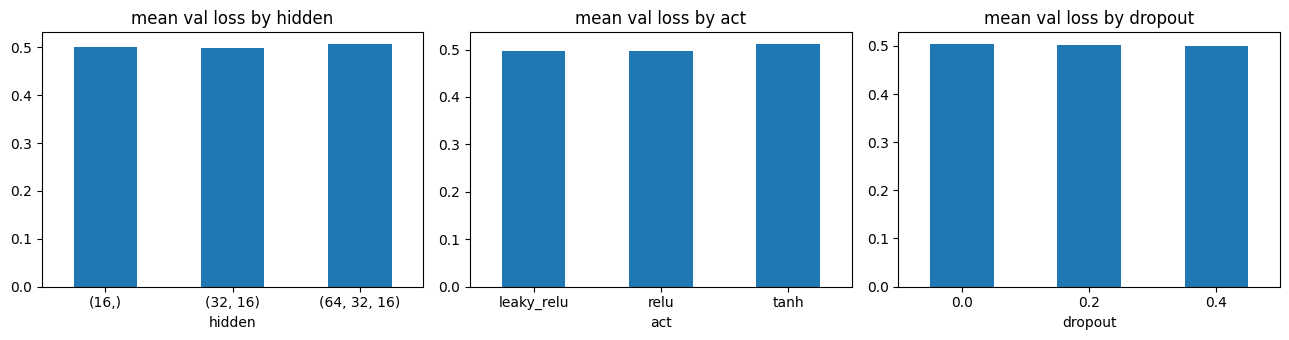

In [7]:
# Effect of each hyper-parameter (mean validation loss across the grid)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, c in zip(ax, ["hidden", "act", "dropout"]):
    tune.groupby(c)["val_loss"].mean().plot.bar(ax=a, rot=0); a.set_title(f"mean val loss by {c}")
plt.tight_layout(); plt.savefig(OUT / "ann_tuning_effects.png", dpi=130); plt.show()

## 5. Train the best configuration & evaluate on the test set

{'hidden': '(32, 16)', 'act': 'leaky_relu', 'dropout': 0.4, 'val_loss': 0.4859828005666318, 'val_acc': 0.7130434782608696, 'epochs': 29}


early stop


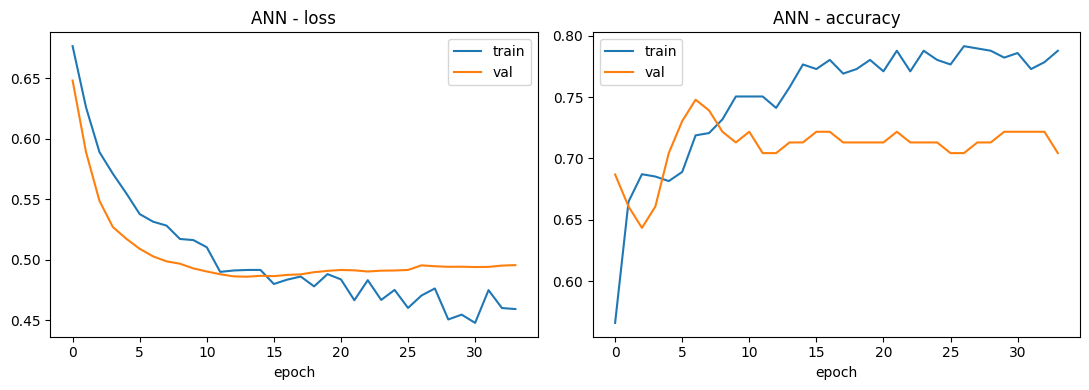

{'accuracy': 0.75, 'precision': 0.6765, 'recall': 0.561, 'f1': 0.6133, 'train_time_s': 0.9918, 'params': 850}


In [8]:
best = tune.iloc[0]; print(best.to_dict())
hidden = eval(best["hidden"])
torch.manual_seed(SEED)
model = ANN(8, hidden, best["act"], best["dropout"]).to(device)
hist, ttime = fit(model, train_dl, val_dl, epochs=200, lr=1e-3, patience=20, verbose=False)
plot_curves(hist, "ANN", "ann_curves.png")

res, pred, ytrue = report(model, test_dl)
res.update(train_time_s=ttime, params=n_params(model), config=best.to_dict())
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in res.items() if k != "config"})
save_result("ANN", res)

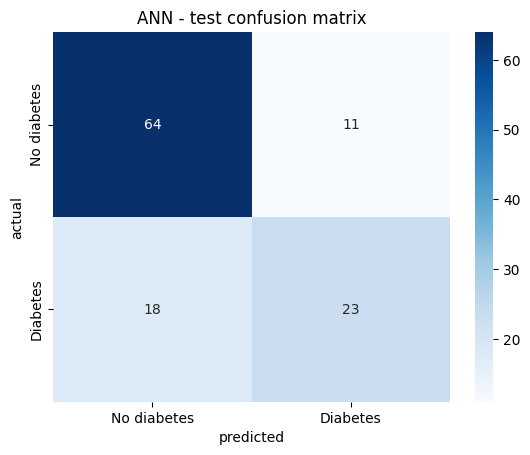

In [9]:
import seaborn as sns
sns.heatmap(confusion_matrix(ytrue, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No diabetes", "Diabetes"], yticklabels=["No diabetes", "Diabetes"])
plt.title("ANN - test confusion matrix"); plt.xlabel("predicted"); plt.ylabel("actual")
plt.savefig(OUT / "ann_confusion.png", dpi=130); plt.show()

## 6. Discussion
- The dataset is small (768 rows), so dropout/early stopping matter more than depth; the tuning table shows deeper nets give little or no benefit.
- Recall on the positive class is the clinically important number (missed diabetics are costly); see the confusion matrix.
- Test set is only ~116 rows, so metrics have wide error bars (a few samples shift accuracy by ~1%).